[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dandi/example-notebooks/blob/master/tutorials/neuromatch_isp_2026/workshop.ipynb)

## Installing requirements

The cell below installs every Python package needed to run this notebook, at fully pinned versions, using [`uv`](https://github.com/astral-sh/uv) for fast resolution. In Colab the cell is collapsed by default — click the ▶ button to run it.

In [ ]:
#@title Installing requirements (click ▶ to run) { display-mode: "form" }
# Colab provides Python 3.13. We install with `uv --system` because Colab's
# kernel runs outside a virtualenv. All versions (direct + transitive) are
# pinned below so the notebook is reproducible regardless of resolver drift.
!pip install -q uv
!uv pip install --system \
    "acres==0.5.0" \
    "aiohappyeyeballs==2.7.1" \
    "aiohttp==3.14.3" \
    "aiosignal==1.4.0" \
    "annotated-types==0.8.0" \
    "arrow==1.4.0" \
    "attrs==26.1.0" \
    "bids-validator-deno==3.0.2" \
    "bidsschematools==1.2.7" \
    "blessed==1.50.0" \
    "certifi==2026.7.22" \
    "cffi==2.1.1" \
    "charset-normalizer==3.4.9" \
    "ci-info==0.4.0" \
    "click==8.5.0" \
    "click-didyoumean==0.3.1" \
    "cloudpickle==3.1.2" \
    "contourpy==1.3.3" \
    "cryptography==50.0.1" \
    "cycler==0.12.1" \
    "dandi==0.82.0" \
    "dandischema==0.14.0" \
    "deno==2.9.8" \
    "dnspython==2.9.2" \
    "donfig==0.8.1.post1" \
    "email-validator==2.3.0" \
    "etelemetry==0.3.1" \
    "fasteners==0.20" \
    "fonttools==4.64.0" \
    "fqdn==1.5.1" \
    "frozenlist==1.8.0" \
    "fscacher==0.5.0" \
    "fsspec==2025.12.0" \
    "google-crc32c==1.8.0" \
    "h5py==3.16.0" \
    "hdmf==4.3.1" \
    "humanize==4.16.0" \
    "idna==3.19" \
    "interleave==0.3.0" \
    "isodate==0.7.2" \
    "isoduration==20.11.0" \
    "jaraco-classes==3.4.0" \
    "jaraco-context==6.1.2" \
    "jaraco-functools==4.6.0" \
    "jeepney==0.9.0" \
    "jinxed==2.1.0" \
    "joblib==1.6.0" \
    "jsonpointer==3.1.1" \
    "jsonschema==4.26.0" \
    "jsonschema-specifications==2025.9.1" \
    "keyring==25.7.0" \
    "keyrings-alt==5.0.2" \
    "kiwisolver==1.5.1" \
    "matplotlib==3.10.0" \
    "ml-dtypes==0.6.0" \
    "more-itertools==10.8.0" \
    "msgspec==0.22.0" \
    "multidict==6.7.1" \
    "natsort==8.4.0" \
    "numcodecs==0.17.1" \
    "numpy==2.1.3" \
    "nwbinspector==0.7.2" \
    "packaging==26.3" \
    "pandas==2.2.3" \
    "pillow==11.3.0" \
    "platformdirs==4.11.7" \
    "propcache==0.5.2" \
    "pycparser==3.0" \
    "pycryptodomex==3.23.0" \
    "pydantic==2.13.5" \
    "pydantic-core==2.46.5" \
    "pydantic-settings==2.16.2" \
    "pynwb==3.1.3" \
    "pyout==0.8.1" \
    "pyparsing==3.3.2" \
    "python-dateutil==2.9.0.post0" \
    "python-dotenv==1.2.3" \
    "pytz==2025.2" \
    "pyyaml==6.0.3" \
    "referencing==0.37.0" \
    "remfile==0.1.15" \
    "requests==2.32.4" \
    "rfc3339-validator==0.1.4" \
    "rfc3987==1.3.8" \
    "rpds-py==2026.6.3" \
    "ruamel-yaml==0.19.1" \
    "secretstorage==3.5.0" \
    "semantic-version==2.10.0" \
    "six==1.17.0" \
    "tenacity==9.1.4" \
    "tensorstore==0.1.85" \
    "tqdm==4.67.3" \
    "typing-extensions==4.16.0" \
    "typing-inspection==0.4.4" \
    "tzdata==2026.3" \
    "uri-template==1.3.0" \
    "urllib3==2.5.0" \
    "wcwidth==0.8.3" \
    "webcolors==25.10.0" \
    "yarl==1.24.5" \
    "zarr==3.4.2" \
    "zarr-checksum==0.4.7"

> **⚠️ Restart runtime after install**
>
> The install may upgrade packages already loaded in the kernel. Go to **Runtime → Restart session**, then **Run all cells below** (skip this install cell on re-run).

# Working with open neurophysiology data: DANDI + NWB

Neuromatch Impact Scholars Program workshop, 30 November 2026. Ben Dichter, CatalystNeuro.

**What you will do**

- **Part A. Find**: search the DANDI Archive from Python and read a dataset's metadata.
- **Part B. Stream**: open a recording session without downloading it, and plot behavior.
- **Part C. Analyze**: look at how single neurons respond during a decision, then reuse the same code on a different lab's data.

**How this works**

- Run the cells in order.
- Each part ends with a cell that prints ✅. Give a thumbs-up in Zoom when you see it.
- Fell behind? Each part starts with a **catch-up cell**. Run it and continue from there.
- Cells marked ✏️ **Your turn** are for you. A solution is hidden right below each one.

In [1]:
import time
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import remfile
from dandi.dandiapi import DandiAPIClient
from pynwb import NWBHDF5IO

warnings.filterwarnings("ignore")

---
# Part A. Find a dataset

A dataset on DANDI is called a **Dandiset**. Each one has a six-digit ID.

You can browse them at [dandiarchive.org](https://dandiarchive.org/dandiset). Here we do the same from Python.

In [2]:
client = DandiAPIClient()

for dandiset in list(client.get_dandisets(search="decision making"))[:10]:
    print(dandiset.identifier, "|", dandiset.get_raw_metadata()["name"][:90])

000004 | A NWB-based dataset and processing pipeline of human single-neuron activity during a decla
000016 | Excitatory and inhibitory subnetworks are equally selective during decision-making and eme
000045 | IBL behavioral data
000060 | Dataset for Finkelstein, Fontolan et al. "Attractor dynamics gate cortical information flo
000149 | IBL ephys data
000212 | Tracking of Drosophila during egg-laying decisions
000247 | Calcium imaging of egg-laying related neurons in head-fixed Drosophila
000250 | High-resolution tracking of Drosophila during egg-laying
000409 | IBL - Brain Wide Map


000447 | Novel-familiar-novel WTrack (CA1-PFC)


We will use **000409**, the International Brain Laboratory (IBL) Brain Wide Map.

Mice turn a wheel to report which side of a screen a visual stimulus appeared on, while Neuropixels probes record from across the brain.

Every Dandiset carries structured metadata. Read it before you download anything.

In [3]:
dandiset = client.get_dandiset("000409", "0.260309.1324")
metadata = dandiset.get_raw_metadata()
summary = metadata["assetsSummary"]

print("Name:      ", metadata["name"])
print("License:   ", metadata["license"])
print("Size:      ", round(summary["numberOfBytes"] / 1e12, 1), "TB in", summary["numberOfFiles"], "files")
print("Subjects:  ", summary["numberOfSubjects"])
print("Species:   ", [s["name"] for s in summary["species"]])
print("Techniques:", [t["name"] for t in summary["measurementTechnique"]])
print()
print("How to cite:", metadata["citation"][:60], "...", metadata["citation"][-110:])

Name:       IBL - Brain Wide Map
License:    ['spdx:CC-BY-4.0']
Size:       49.7 TB in 2048 files
Subjects:   139
Species:    ['Mus musculus - House mouse']
Techniques: ['surgical technique', 'multi electrode extracellular electrophysiology recording technique', 'analytical technique', 'behavioral technique', 'spike sorting technique']

How to cite: International Brain Laboratory; Benson, Brandon; Benson, Jul ... ide Map (Version 0.260309.1324) [Data set]. DANDI Archive. https://doi.org/10.48324/dandi.000409/0.260309.1324


💡 We asked for a specific **version** (`0.260309.1324`).
A published version never changes and has its own DOI, so your analysis stays reproducible.

This Dandiset is far too large to download. That is fine. We only need one file, and only parts of it.

Files in a Dandiset are called **assets**. Let's list the ones for one mouse.

In [4]:
assets = list(dandiset.get_assets_with_path_prefix("sub-DY-011/"))

for asset in assets:
    if asset.path.endswith(".nwb"):
        print(f"{asset.size / 1e9:6.1f} GB   {asset.path}")

  42.5 GB   sub-DY-011/sub-DY-011_ses-7bee9f09-a238-42cf-b499-f51f765c6ded_desc-raw_ecephys.nwb
  44.6 GB   sub-DY-011/sub-DY-011_ses-cf43dbb1-6992-40ec-a5f9-e8e838d0f643_desc-raw_ecephys.nwb
  49.5 GB   sub-DY-011/sub-DY-011_ses-741979ce-3f10-443a-8526-2275620c8473_desc-raw_ecephys.nwb
  54.0 GB   sub-DY-011/sub-DY-011_ses-36280321-555b-446d-9b7d-c2e17991e090_desc-raw_ecephys.nwb
   0.3 GB   sub-DY-011/sub-DY-011_ses-cf43dbb1-6992-40ec-a5f9-e8e838d0f643_desc-processed_behavior+ecephys.nwb
   0.4 GB   sub-DY-011/sub-DY-011_ses-7bee9f09-a238-42cf-b499-f51f765c6ded_desc-processed_behavior+ecephys.nwb
   0.4 GB   sub-DY-011/sub-DY-011_ses-36280321-555b-446d-9b7d-c2e17991e090_desc-processed_behavior+ecephys.nwb
   0.5 GB   sub-DY-011/sub-DY-011_ses-741979ce-3f10-443a-8526-2275620c8473_desc-processed_behavior+ecephys.nwb


Each session has two NWB files:

- `desc-raw`: the raw voltage recordings. Very large.
- `desc-processed`: spike times, behavior and trial information. Much smaller, and what most analyses need.

In [5]:
asset = dandiset.get_asset_by_path(
    "sub-DY-011/sub-DY-011_ses-cf43dbb1-6992-40ec-a5f9-e8e838d0f643_desc-processed_behavior+ecephys.nwb"
)
print(f"✅ Part A done. Selected a {asset.size / 1e6:.0f} MB file: {asset.path.split('/')[-1]}")

✅ Part A done. Selected a 345 MB file: sub-DY-011_ses-cf43dbb1-6992-40ec-a5f9-e8e838d0f643_desc-processed_behavior+ecephys.nwb


### ✏️ Your turn

Search DANDI for a topic from your own project. How many Dandisets match? What species do the first few use?

In [6]:
my_search = "hippocampus"  # change me

In [7]:
#@title Solution (click to show) { display-mode: "form" }
my_search = "hippocampus"

results = list(client.get_dandisets(search=my_search))
print(len(results), "Dandisets match", repr(my_search))
for result in results[:5]:
    result_metadata = result.get_raw_metadata()
    species = [s["name"] for s in result_metadata.get("assetsSummary", {}).get("species", [])]
    print(result.identifier, "|", result_metadata["name"][:60], "|", species)

68 Dandisets match 'hippocampus'
000003 | Physiological Properties and Behavioral Correlates of Hippoc | ['House mouse']
000030 | Allen Brain Observatory Neuropixels recording | []
000044 | Diversity in neural firing dynamics supports both rigid and  | ['Rattus norvegicus - Norway rat']
000054 | Plitt & Giocomo (2021) Experience Dependent Contextual Codes | ['Mus musculus - House mouse']
000059 | Cooling of Medial Septum Reveals Theta Phase Lag Coordinatio | ['Rattus norvegicus - Norway rat']


---
# Part B. Stream a session and look at behavior

**Catch-up cell.** Run this if you are starting here.

In [8]:
client = DandiAPIClient()
dandiset = client.get_dandiset("000409", "0.260309.1324")
asset = dandiset.get_asset_by_path(
    "sub-DY-011/sub-DY-011_ses-cf43dbb1-6992-40ec-a5f9-e8e838d0f643_desc-processed_behavior+ecephys.nwb"
)

This function opens a file on DANDI **without downloading it**.

NWB files are organized so that a program can jump straight to the piece it needs. `remfile` fetches only those pieces over the network.

In [9]:
def open_nwb(asset):
    """Open an NWB file on DANDI by streaming. Nothing is downloaded up front."""
    url = asset.get_content_url(follow_redirects=1, strip_query=True)
    h5_file = h5py.File(remfile.File(url), mode="r")
    return NWBHDF5IO(file=h5_file, load_namespaces=True).read()


start = time.time()
nwbfile = open_nwb(asset)
print(f"Opened a {asset.size / 1e6:.0f} MB file in {time.time() - start:.0f} seconds")

Opened a 345 MB file in 7 seconds


What is inside? Every NWB file has the same layout, whichever lab made it.

In [10]:
print("Lab:        ", nwbfile.lab, "|", nwbfile.institution)
print("Session:    ", nwbfile.session_start_time.date())
print("Subject:    ", nwbfile.subject.subject_id, "|", nwbfile.subject.species, "|", nwbfile.subject.sex)
print("Trials:     ", len(nwbfile.trials))
print("Neurons:    ", len(nwbfile.units), "units")
print("Processing: ", list(nwbfile.processing))

Lab:         danlab | University of California Berkeley
Session:     2020-02-08
Subject:     DY_011 | Mus musculus | M
Trials:      402
Neurons:     329 units
Processing:  ['lick_times', 'motion_energy', 'passive_protocol', 'pose_estimation', 'pupil', 'wheel']


### The trials table

Each row is one trial of the task. Tables in NWB convert to pandas in one line.

In [11]:
trials = nwbfile.trials.to_dataframe()
trials.head()

,start_time,stop_time,quiescence_period,gabor_stimulus_onset_time,auditory_cue_time,wheel_movement_onset_time,choice_registration_time,feedback_time,gabor_stimulus_offset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reward_volume_uL,probability_left,block_type,block_index
id,,,,,,,,,,,,,,,,,
0,7.662600,11.392621,0.403646,8.681632,8.590174,9.349499,9.842511,9.842616,10.892511,25.00,left,clockwise,True,1.5,0.5,unbiased,0
1,11.786321,14.859244,0.567621,12.781488,12.782455,13.039499,13.304331,13.304436,14.359164,12.50,left,clockwise,True,1.5,0.5,unbiased,0
2,15.230443,21.059457,0.580503,19.164950,19.166017,19.366499,19.506051,19.506149,20.559377,12.50,left,clockwise,True,1.5,0.5,unbiased,0
3,21.448755,23.809251,0.479755,21.980902,21.982002,21.965499,22.247153,22.247242,23.309236,25.00,right,counter_clockwise,True,1.5,0.5,unbiased,0
4,24.182748,26.598369,0.459729,24.698097,24.698963,24.850499,25.030655,25.030763,26.098257,6.25,left,clockwise,True,1.5,0.5,unbiased,0


Not sure what a column means? The description is stored in the file, next to the data.

In [12]:
for column in ["gabor_stimulus_contrast", "gabor_stimulus_side", "mouse_wheel_choice", "wheel_movement_onset_time"]:
    print(f"{column}:\n    {nwbfile.trials[column].description}\n")

gabor_stimulus_contrast:
    Contrast of the Gabor patch as a percentage (0, 6.25, 12.5, 25, or 100). Uniformly sampled across trials. At 0% contrast (no visible stimulus), mice can still perform above chance using block probability prior.

gabor_stimulus_side:
    Side on the screen where stimulus was presented: 'left' or 'right'. Even at 0% contrast (no visible stimulus), a side is assigned to the stimulus for the trial, enabling the mice to perform a correct response using prior knowledge of the block distribution. 

mouse_wheel_choice:
    Mouse's response: 'counter_clockwise' (counter_clockwise wheel turn moving stimulus leftward), 'clockwise' (clockwise wheel turn moving stimulus rightward), or 'none' (no response within 60s timeout). clockwise and counter_clockwise are wheel movements as seen from the perspective of the mouse

wheel_movement_onset_time:
    Time of first detected wheel movement (>= 0.1 radians threshold) after the go cue.



### Did the mouse do the task?

A **psychometric curve** shows how choices depend on how visible the stimulus was.

We give the contrast a sign: negative for a stimulus on the left, positive for the right.

In [13]:
side_sign = trials["gabor_stimulus_side"].map({"left": -1, "right": 1})
trials["signed_contrast"] = trials["gabor_stimulus_contrast"] * side_sign

# Which wheel direction reports which side? Check with the rewarded trials.
pd.crosstab(trials["gabor_stimulus_side"], trials["mouse_wheel_choice"], values=trials["is_mouse_rewarded"], aggfunc="mean").round(2)

mouse_wheel_choice,clockwise,counter_clockwise,none
gabor_stimulus_side,,,
left,1.0,0.0,0.0
right,0.0,1.0,NaN


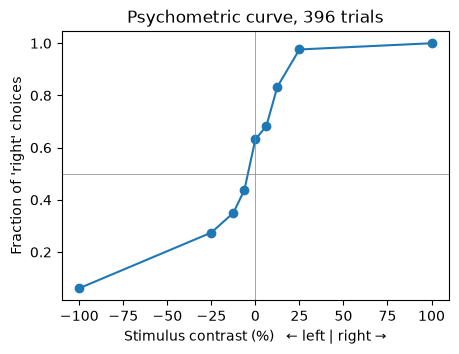

✅ Part B done


In [14]:
went = trials[trials["mouse_wheel_choice"].isin(["clockwise", "counter_clockwise"])]
chose_right = went["mouse_wheel_choice"] == "counter_clockwise"
curve = chose_right.groupby(went["signed_contrast"]).mean()

plt.figure(figsize=(5, 3.5))
plt.plot(curve.index, curve.values, "o-")
plt.axhline(0.5, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)
plt.xlabel("Stimulus contrast (%)   ← left | right →")
plt.ylabel("Fraction of 'right' choices")
plt.title(f"Psychometric curve, {len(went)} trials")
plt.show()

print("✅ Part B done")

### ✏️ Your turn

Is the mouse faster when the stimulus is easier to see?

Compute the reaction time (`wheel_movement_onset_time` minus `gabor_stimulus_onset_time`) and plot its median for each contrast.

In [15]:
trials["reaction_time"] = ...

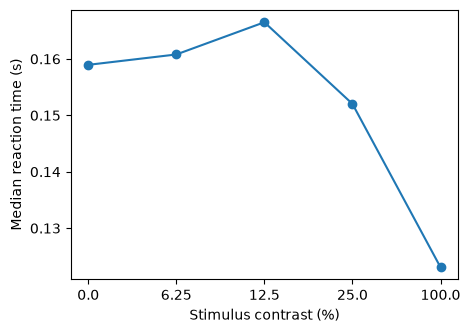

In [16]:
#@title Solution (click to show) { display-mode: "form" }
trials["reaction_time"] = trials["wheel_movement_onset_time"] - trials["gabor_stimulus_onset_time"]
median_rt = trials.groupby("gabor_stimulus_contrast")["reaction_time"].median()

plt.figure(figsize=(5, 3.5))
plt.plot(median_rt.index.astype(str), median_rt.values, "o-")
plt.xlabel("Stimulus contrast (%)")
plt.ylabel("Median reaction time (s)")
plt.show()

---
# Part C. Neurons during a decision

**Catch-up cell.** Run this if you are starting here.

In [17]:
client = DandiAPIClient()
dandiset = client.get_dandiset("000409", "0.260309.1324")
asset = dandiset.get_asset_by_path(
    "sub-DY-011/sub-DY-011_ses-cf43dbb1-6992-40ec-a5f9-e8e838d0f643_desc-processed_behavior+ecephys.nwb"
)

def open_nwb(asset):
    """Open an NWB file on DANDI by streaming. Nothing is downloaded up front."""
    url = asset.get_content_url(follow_redirects=1, strip_query=True)
    h5_file = h5py.File(remfile.File(url), mode="r")
    return NWBHDF5IO(file=h5_file, load_namespaces=True).read()


if "nwbfile" not in globals():
    nwbfile = open_nwb(asset)
trials = nwbfile.trials.to_dataframe()

### The units table

Each row is one **unit**: a putative neuron found by spike sorting.

Some columns hold a lot of data per unit, such as every spike time. We leave those out for now and read them only when needed.

In [18]:
big_columns = {"spike_times", "spike_amplitudes_uV", "spike_distances_from_probe_tip_um", "waveform_mean", "electrodes", "max_electrode"}
units = nwbfile.units.to_dataframe(exclude=big_columns)

# Where in the brain was each unit? Look up the electrode it was recorded on.
electrodes = nwbfile.electrodes.to_dataframe()
max_electrode = nwbfile.units["max_electrode"].data[:]
units["location"] = electrodes["location"].values[max_electrode]

units[["kilosort2_label", "firing_rate", "location"]].head()

,kilosort2_label,firing_rate,location
id,,,
0,mua,20.073377,Central medial nucleus of the thalamus
1,good,10.236213,Central medial nucleus of the thalamus
2,good,8.044924,Central medial nucleus of the thalamus
3,mua,0.012792,Central medial nucleus of the thalamus
4,mua,2.128721,Central medial nucleus of the thalamus


In [19]:
units["location"].value_counts().head(8)

location
Primary motor area Layer 5                 75
Paraventricular nucleus of the thalamus    63
Primary motor area Layer 6a                43
third ventricle                            33
fimbria                                    26
Primary motor area Layer 2/3               16
root                                       14
Central medial nucleus of the thalamus     13
Name: count, dtype: int64

This probe passed through **primary motor cortex**. Let's pick one well-isolated unit there and read its spike times.

Only this unit's spikes are fetched from DANDI.

In [20]:
unit_id = 163

spike_times = nwbfile.units["spike_times"][unit_id]
print(f"Unit {unit_id} in {units.loc[unit_id, 'location']}: {len(spike_times)} spikes, quality label '{units.loc[unit_id, 'kilosort2_label']}'")

Unit 163 in Primary motor area Layer 6a: 32193 spikes, quality label 'good'


### Align spikes to an event

The standard move in systems neuroscience: cut out the spikes around each event, and stack the trials.

In [21]:
def align(spike_times, event_times, window=(-0.5, 1.0)):
    """For each event, return the spike times relative to that event."""
    aligned = []
    for event in event_times:
        first, last = np.searchsorted(spike_times, [event + window[0], event + window[1]])
        aligned.append(spike_times[first:last] - event)
    return aligned


def plot_aligned(spike_times, event_times, window=(-0.5, 1.0), bin_size=0.025, axes=None, color="k", label=None):
    """Raster on top, firing rate (PSTH) below."""
    if axes is None:
        _, axes = plt.subplots(2, 1, figsize=(5, 5), sharex=True, height_ratios=[2, 1])
    aligned = align(spike_times, np.asarray(event_times), window)
    offset = len(axes[0].collections)
    axes[0].eventplot(aligned, lineoffsets=np.arange(len(aligned)) + offset, colors=color, linewidths=0.6)
    bins = np.arange(window[0], window[1] + bin_size, bin_size)
    rate = np.histogram(np.concatenate(aligned), bins)[0] / len(aligned) / bin_size
    axes[1].plot(bins[:-1] + bin_size / 2, rate, color=color, label=label)
    axes[0].set_ylabel("Trial")
    axes[1].set_ylabel("Spikes / s")
    for ax in axes:
        ax.axvline(0, color="gray", lw=0.5)
    return axes

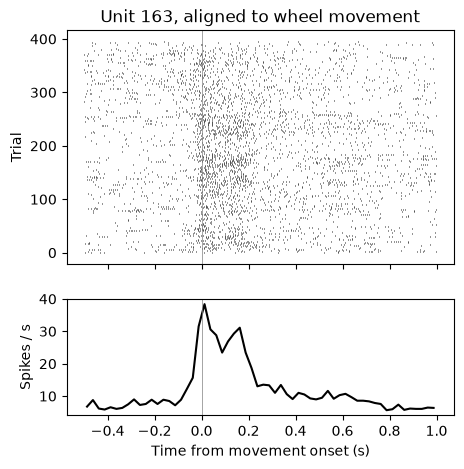

In [22]:
moved = trials.dropna(subset=["wheel_movement_onset_time", "gabor_stimulus_onset_time"])

axes = plot_aligned(spike_times, moved["wheel_movement_onset_time"])
axes[0].set_title(f"Unit {unit_id}, aligned to wheel movement")
axes[1].set_xlabel("Time from movement onset (s)")
plt.show()

The neuron fires when the mouse starts to turn the wheel.

Is the response about **seeing** the stimulus or about **moving**? Align the same spikes to each event and compare.

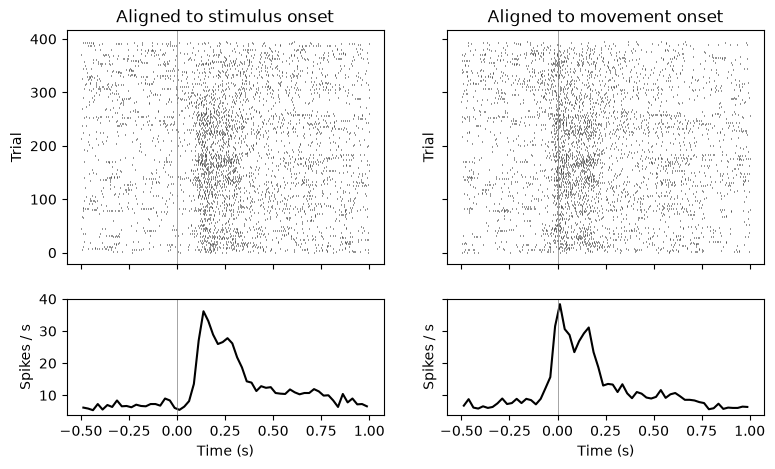

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True, sharey="row", height_ratios=[2, 1])

plot_aligned(spike_times, moved["gabor_stimulus_onset_time"], axes=axes[:, 0])
plot_aligned(spike_times, moved["wheel_movement_onset_time"], axes=axes[:, 1])

axes[0, 0].set_title("Aligned to stimulus onset")
axes[0, 1].set_title("Aligned to movement onset")
axes[1, 0].set_xlabel("Time (s)")
axes[1, 1].set_xlabel("Time (s)")
plt.show()

### ✏️ Your turn

Does this neuron care which way the wheel turns?

Plot the movement-aligned response separately for `clockwise` and `counter_clockwise` choices. `plot_aligned` takes `axes`, `color` and `label`.

Then try another unit. Units 176 and 190 are good candidates.

In [24]:
clockwise = moved[moved["mouse_wheel_choice"] == "clockwise"]
counter_clockwise = ...

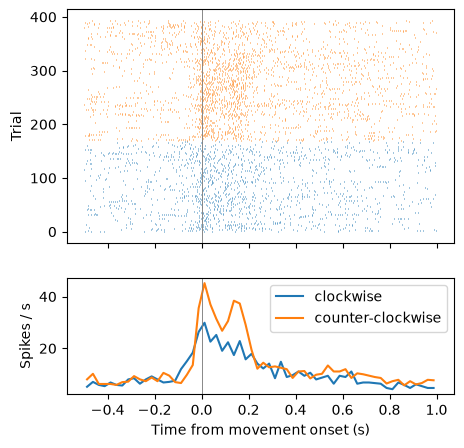

In [25]:
#@title Solution (click to show) { display-mode: "form" }
clockwise = moved[moved["mouse_wheel_choice"] == "clockwise"]
counter_clockwise = moved[moved["mouse_wheel_choice"] == "counter_clockwise"]

axes = plot_aligned(spike_times, clockwise["wheel_movement_onset_time"], color="tab:blue", label="clockwise")
plot_aligned(spike_times, counter_clockwise["wheel_movement_onset_time"], axes=axes, color="tab:orange", label="counter-clockwise")
axes[1].legend()
axes[1].set_xlabel("Time from movement onset (s)")
plt.show()

### Same code, different lab

Here is a file from a different institute, species of experiment and recording method: two-photon calcium imaging of mouse visual cortex from the Allen Institute (Dandiset 000728).

The function we wrote for the IBL file opens it unchanged. That is the point of a data standard.

In [26]:
allen_dandiset = client.get_dandiset("000728", "0.240827.1809")
allen_asset = allen_dandiset.get_asset_by_path(
    "sub-495727015/sub-495727015_ses-501559087-StimB_behavior+image+ophys.nwb"
)
allen_nwbfile = open_nwb(allen_asset)

print("Institution:", allen_nwbfile.institution)
print("Processing: ", list(allen_nwbfile.processing))

df_over_f = allen_nwbfile.processing["ophys"]["DfOverF"]["DfOverF"]
print("ΔF/F array: ", df_over_f.data.shape, "(time points × cells)")

Institution: Allen Institute for Brain Science
Processing:  ['behavior', 'ophys']
ΔF/F array:  (113888, 174) (time points × cells)


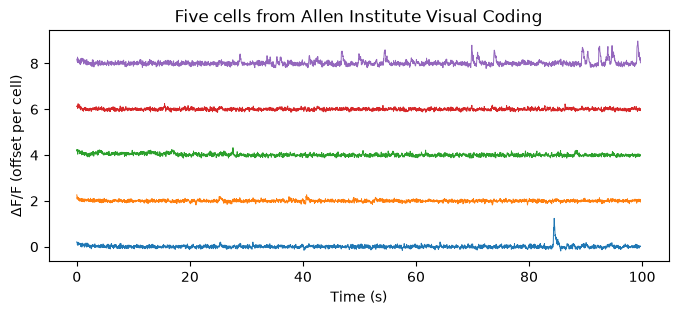

✅ Part C done


In [27]:
traces = df_over_f.data[:3000, :5]  # only this slice is fetched
time_axis = df_over_f.timestamps[:3000]

plt.figure(figsize=(8, 3))
plt.plot(time_axis - time_axis[0], traces + np.arange(5) * 2, lw=0.7)
plt.xlabel("Time (s)")
plt.ylabel("ΔF/F (offset per cell)")
plt.title("Five cells from Allen Institute Visual Coding")
plt.show()

print("✅ Part C done")

---
# Before you share your work

A short checklist for the micropublication:

- **Pin the version** of every Dandiset you use, as we did above.
- **Cite the Dandiset** with the citation from its metadata, alongside the paper.
- **Record your environment.** The cell below prints the versions used here.
- **Share the notebook** so others can rerun it. Streaming means they need no downloads either.
- **Used an AI assistant?** Say so, and check every result yourself.

In [28]:
import dandi, pynwb, hdmf

citation = dandiset.get_raw_metadata()["citation"]
print("Data:", citation[:60], "...", citation[-110:])
print()
for module in (dandi, pynwb, hdmf, h5py, remfile, np, pd):
    print(f"{module.__name__}=={module.__version__}")

Data: International Brain Laboratory; Benson, Brandon; Benson, Jul ... ide Map (Version 0.260309.1324) [Data set]. DANDI Archive. https://doi.org/10.48324/dandi.000409/0.260309.1324

dandi==0.82.0
pynwb==3.1.3
hdmf==4.3.1
h5py==3.16.0
remfile==0.1.15
numpy==2.5.4
pandas==2.3.3


# Where to go next

- **Browse without code**: open any NWB file in [Neurosift](https://neurosift.app) from its DANDI page.
- **More examples**: [DANDI example notebooks](https://github.com/dandi/example-notebooks), including a [longer tour of this IBL dataset](https://github.com/dandi/example-notebooks/blob/master/000409/IBL/bwm_usage_notebook.ipynb).
- **Learn NWB**: [PyNWB tutorials](https://pynwb.readthedocs.io/en/stable/tutorials/index.html) and the [NWB overview](https://nwb-overview.readthedocs.io).
- **Search by metadata**: the [advanced search tutorial](https://github.com/dandi/example-notebooks/tree/master/tutorials/neurodatarehack_2024).
- **Ask for help**: [DANDI helpdesk](https://github.com/dandi/helpdesk/issues/new/choose) and the [NWB helpdesk](https://github.com/NeurodataWithoutBorders/helpdesk/discussions).
- **Slow connection?** `asset.download("file.nwb")` saves a file locally, and `pynwb.read_nwb("file.nwb")` opens it.